In [1]:
import polars as pl
import typol as tp
from catboost import CatBoostClassifier

from Answer import CompleteAnswer, PredictedAndActualQ1, AnswerParts1_6WithQ1_V445_Q3a15_Q3a14, \
    FeatureImportance

In [2]:
from is_reader_util import train_predict_is_reader_parts_1_6, predict_is_reader_parts_1_6, split_data_for_parts_1_6, \
    visualize_is_reader_predictions, is_reader_PCA


def goal1a(data: tp.DataFrame[CompleteAnswer]) -> CatBoostClassifier:
    is_reader_data = data.transform(AnswerParts1_6WithQ1_V445_Q3a15_Q3a14)
    X_train_reader,X_test_reader,y_train_reader,y_test_reader = split_data_for_parts_1_6(is_reader_data)
    # find_best_params_for_catboost(is_reader_data)
    is_reader_predictor = train_predict_is_reader_parts_1_6(X_train_reader, y_train_reader)
    is_reader_predictions: tp.DataFrame[PredictedAndActualQ1] = predict_is_reader_parts_1_6(is_reader_predictor, X_test_reader, y_test_reader)
    visualize_is_reader_predictions(is_reader_predictions)

    return is_reader_predictor

In [3]:
from habits_util import predict_habits, visualize_predict_habits, split_data_for_habits, train_predict_habits


def goal1b(data: tp.DataFrame[CompleteAnswer]) -> CatBoostClassifier:
    X_train_habits,X_test_habits,y_train_habits,y_test_habits = split_data_for_habits(data)
    habits_predictor = train_predict_habits(X_train_habits, y_train_habits)
    habits_predictions = predict_habits(habits_predictor, X_test_habits, y_test_habits)
    visualize_predict_habits(habits_predictions)

    return habits_predictor

In [4]:
def goal2(predictor: CatBoostClassifier) -> None:
    is_reader_features: tp.DataFrame[FeatureImportance] = is_reader_PCA(predictor)
    print(is_reader_features.head(20))

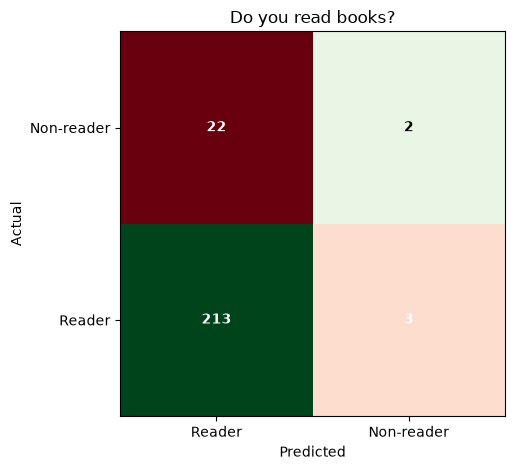

   Feature Id  Importances
0       Q62_1     5.661379
1       Q67_1     5.107897
2        Q6_2     5.038741
3          Q7     4.704791
4       Q3b_8     2.986904
5          Q2     2.564704
6       Q63_1     2.363171
7        Q5_6     2.251232
8       Q3a_1     1.936866
9       Q3c_7     1.647613
10      Q3a_8     1.643647
11      Q70_2     1.550959
12      T11_9     1.526659
13      Q3b_5     1.520010
14    Elukoht     1.397165
15      T11_7     1.359123
16      Q3d_2     1.344668
17      Q3a_5     1.313143
18      T22_3     1.257581
19       Q6_4     1.190585


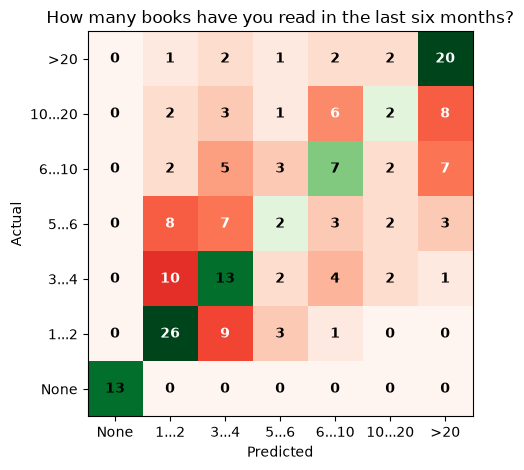

   Feature Id  Importances
0          Q1     9.021132
1       Q12_1     5.702062
2      Q11a_1     5.097466
3     Q29_1_6     4.433056
4       Q63_1     2.603008
5      Q3a_15     2.523257
6       Q3d_4     1.781283
7       Q30_1     1.600447
8       Q15_2     0.846673
9       Q3c_6     0.628844
10       Q6_2     0.584491
11        T19     0.573954
12       Q9_1     0.556466
13     Q3a_16     0.505071
14      Q3a_8     0.493109
15        T18     0.486836
16    Q53_1_6     0.462698
17      Q31_8     0.454007
18      Q36_1     0.442698
19      Q6_10     0.437826


In [5]:
# TODO Determine the feasibility of a model for recommending books to a person according to their answers

def main():
    raw_data: pl.DataFrame = pl.read_csv("Lugeja25.tab", has_header=True, separator="\t")
    typed_data: tp.DataFrame[CompleteAnswer] = tp.DataFrame(CompleteAnswer, values=raw_data)

    is_reader_predictor = goal1a(typed_data)
    goal2(is_reader_predictor)
    habits_predictor = goal1b(typed_data)
    goal2(habits_predictor)

if __name__ == "__main__":
    main()